# 🏨 Hotel Reservation Cancellation Prediction — ANN  Project

## Importing Libraries

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, callbacks

import joblib

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU Available: []


In [33]:
df = pd.read_csv('Hotel Reservations.csv')
print("Shape:", df.shape)
df.head()


Shape: (36275, 19)


,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [34]:
# Structure & data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

In [35]:
# Statistical summary of numerical columns
df.describe().T


,count,mean,std,min,25%,50%,75%,max
no_of_adults,36275.0,1.844962,0.518715,0.0,2.0,2.00,2.0,4.0
no_of_children,36275.0,0.105279,0.402648,0.0,0.0,0.00,0.0,10.0
no_of_weekend_nights,36275.0,0.810724,0.870644,0.0,0.0,1.00,2.0,7.0
no_of_week_nights,36275.0,2.204300,1.410905,0.0,1.0,2.00,3.0,17.0
required_car_parking_space,36275.0,0.030986,0.173281,0.0,0.0,0.00,0.0,1.0
lead_time,36275.0,85.232557,85.930817,0.0,17.0,57.00,126.0,443.0
arrival_year,36275.0,2017.820427,0.383836,2017.0,2018.0,2018.00,2018.0,2018.0
arrival_month,36275.0,7.423653,3.069894,1.0,5.0,8.00,10.0,12.0
arrival_date,36275.0,15.596995,8.740447,1.0,8.0,16.00,23.0,31.0
repeated_guest,36275.0,0.025637,0.158053,0.0,0.0,0.00,0.0,1.0


In [36]:
# Statistical summary of categorical columns
df.describe(include='object').T


,count,unique,top,freq
Booking_ID,36275,36275,INN36275,1
type_of_meal_plan,36275,4,Meal Plan 1,27835
room_type_reserved,36275,7,Room_Type 1,28130
market_segment_type,36275,5,Online,23214
booking_status,36275,2,Not_Canceled,24390


In [37]:
import pandas as pd

# Create a table of column descriptions
column_info = {
    "Booking_ID": "Unique identifier for each booking",
    "no_of_adults": "Number of adults in the booking",
    "no_of_children": "Number of children in the booking",
    "no_of_weekend_nights": "Nights booked that fall on weekends",
    "no_of_week_nights": "Nights booked that fall on weekdays",
    "type_of_meal_plan": "Meal plan chosen (e.g., Breakfast, Full board)",
    "required_car_parking_space": "Whether a parking space was requested (0=No, 1=Yes)",
    "room_type_reserved": "Type of room booked (e.g., Deluxe, Standard)",
    "lead_time": "Days between booking date and arrival date",
    "arrival_year": "Year of arrival",
    "arrival_month": "Month of arrival (1–12)",
    "arrival_date": "Day of the month (1–31)",
    "market_segment_type": "Source of booking (e.g., Online, Corporate, Direct)",
    "repeated_guest": "Whether the guest booked before (0=No, 1=Yes)",
    "no_of_previous_cancellations": "Number of past cancellations by the guest",
    "no_of_previous_bookings_not_canceled": "Number of past successful bookings",
    "avg_price_per_room": "Average price per room for the booking",
    "no_of_special_requests": "Number of special requests (e.g., extra bed, late check-in)",
    "booking_status": "Target variable: whether booking was Canceled or Not_Canceled"
}

# Convert to DataFrame for display
column_info_df = pd.DataFrame(list(column_info.items()), columns=["Column Name", "Description"])
column_info_df


,Column Name,Description
0,Booking_ID,Unique identifier for each booking
1,no_of_adults,Number of adults in the booking
2,no_of_children,Number of children in the booking
3,no_of_weekend_nights,Nights booked that fall on weekends
4,no_of_week_nights,Nights booked that fall on weekdays
5,type_of_meal_plan,"Meal plan chosen (e.g., Breakfast, Full board)"
6,required_car_parking_space,"Whether a parking space was requested (0=No, 1..."
7,room_type_reserved,"Type of room booked (e.g., Deluxe, Standard)"
8,lead_time,Days between booking date and arrival date
9,arrival_year,Year of arrival


## Handle incorrect datatype 

In [38]:
# Convert binary numeric features to categorical
df['required_car_parking_space'] = df['required_car_parking_space'].astype('object')
df['repeated_guest'] = df['repeated_guest'].astype('object')

# Convert other categorical features stored as object to category
cat_features = [
    'type_of_meal_plan'
    
]
for col in cat_features:
    df[col] = df[col].astype('object')




In [39]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  object 
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-null  int64  
 11  arrival_date   

### 2.2  Missing Values & Duplicates

*


In [40]:
# Missing value audit
missing_report = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('missing_count', ascending=False)

print("Missing Value Report:")
print(missing_report)

# Duplicate rows audit
n_duplicates = df.duplicated().sum()
print(f"\nNumber of fully duplicated rows: {n_duplicates}")


Missing Value Report:
                                      missing_count  missing_pct
Booking_ID                                        0          0.0
no_of_adults                                      0          0.0
no_of_children                                    0          0.0
no_of_weekend_nights                              0          0.0
no_of_week_nights                                 0          0.0
type_of_meal_plan                                 0          0.0
required_car_parking_space                        0          0.0
room_type_reserved                                0          0.0
lead_time                                         0          0.0
arrival_year                                      0          0.0
arrival_month                                     0          0.0
arrival_date                                      0          0.0
market_segment_type                               0          0.0
repeated_guest                                    0          0.0
no_

### 2.3 Target Class Balance — `booking_status`


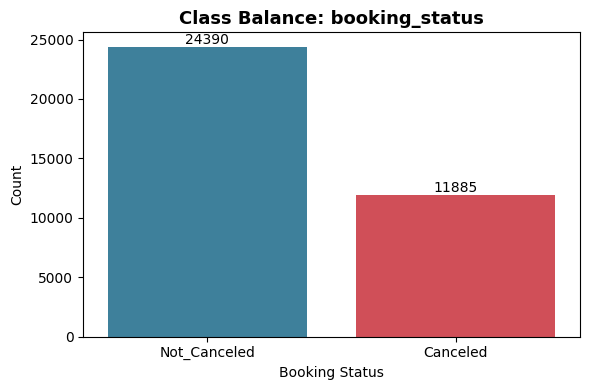

booking_status
Not_Canceled    67.2
Canceled        32.8
Name: proportion, dtype: float64 %


In [8]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='booking_status', hue='booking_status',
                    palette=['#2E86AB', '#E63946'], legend=False)
ax.set_title('Class Balance: booking_status', fontsize=13, fontweight='bold')
ax.set_xlabel('Booking Status')
ax.set_ylabel('Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

print(df['booking_status'].value_counts(normalize=True).round(3) * 100, "%")


### Feature Distribution Analysis

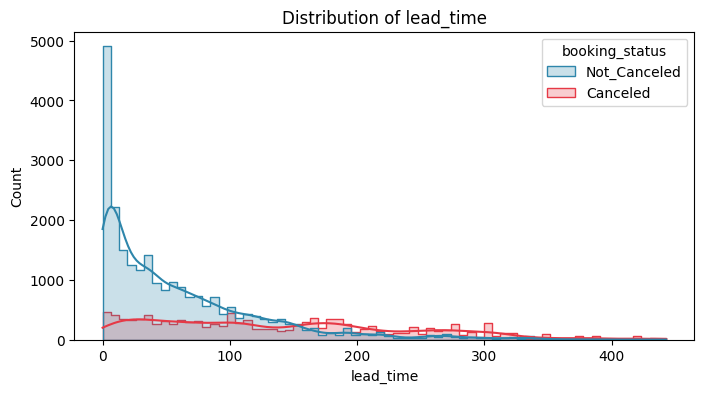

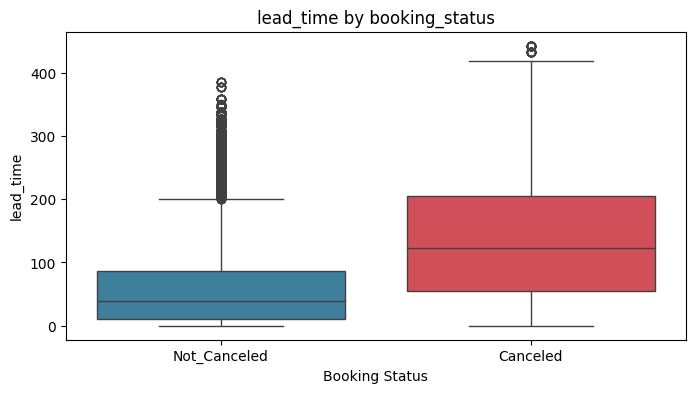

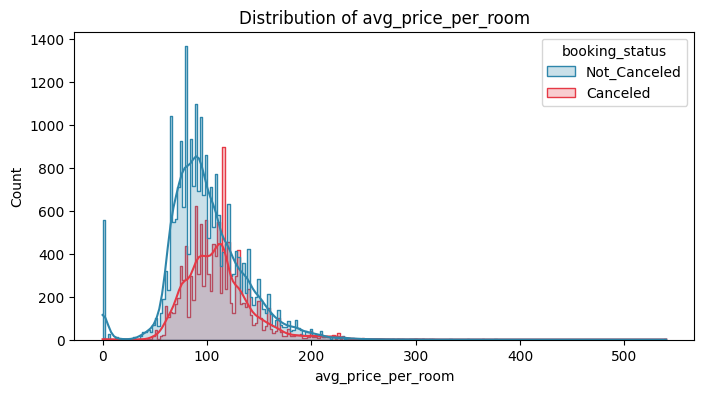

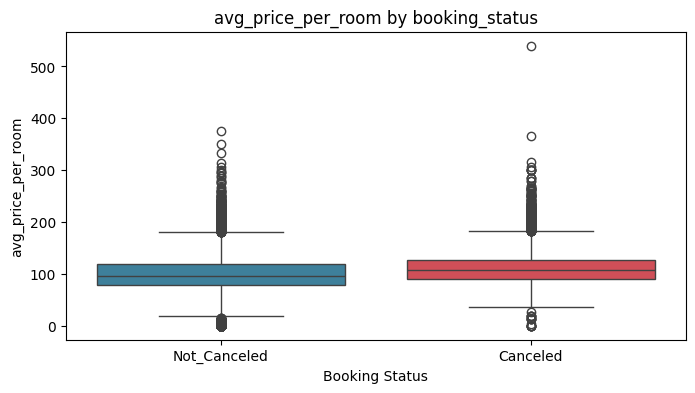

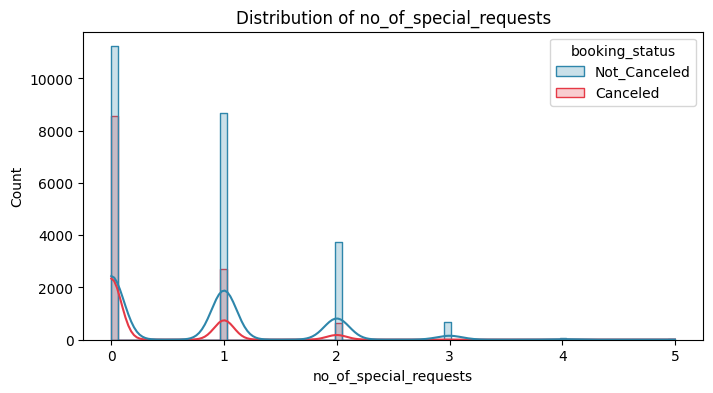

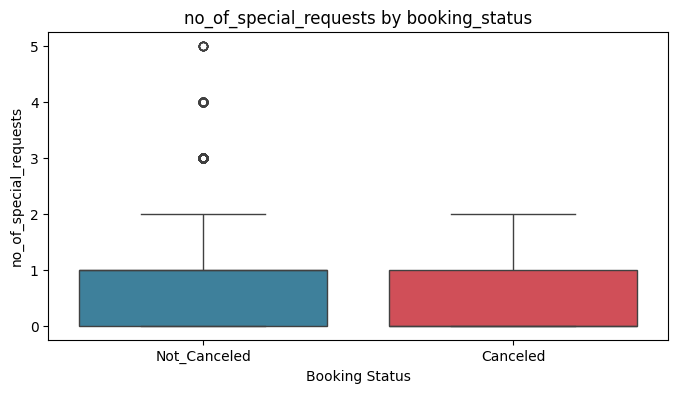

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['lead_time', 'avg_price_per_room', 'no_of_special_requests']

for col in num_cols:
    # Histogram
    plt.figure(figsize=(8,4))
    sns.histplot(data=df, x=col, hue='booking_status', kde=True,
                 palette=['#2E86AB', '#E63946'], element='step')
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

    # Boxplot
    plt.figure(figsize=(8,4))
    sns.boxplot(data=df, x='booking_status', y=col, hue='booking_status',
                palette=['#2E86AB', '#E63946'], legend=False)
    plt.title(f'{col} by booking_status')
    plt.xlabel("Booking Status")
    plt.ylabel(col)
    plt.show()


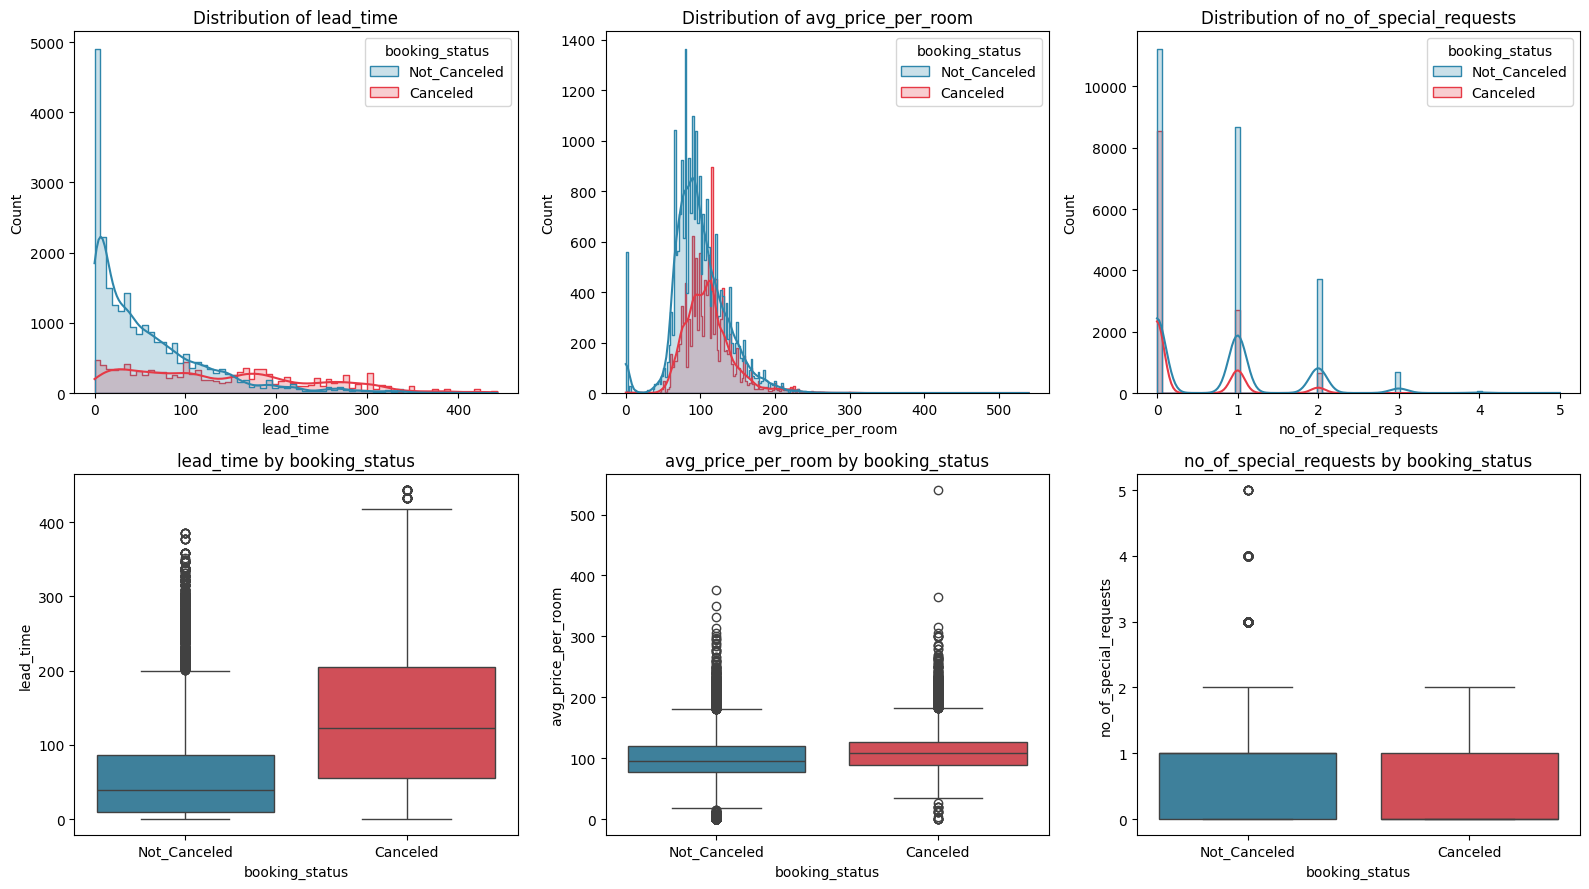

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

num_cols = ['lead_time', 'avg_price_per_room', 'no_of_special_requests']

for i, col in enumerate(num_cols):
    sns.histplot(data=df, x=col, hue='booking_status', kde=True, ax=axes[0, i],
                 palette=['#2E86AB', '#E63946'], element='step')
    axes[0, i].set_title(f'Distribution of {col}')

    sns.boxplot(data=df, x='booking_status', y=col, hue='booking_status', ax=axes[1, i],
                palette=['#2E86AB', '#E63946'], legend=False)
    axes[1, i].set_title(f'{col} by booking_status')

plt.tight_layout()
plt.show()


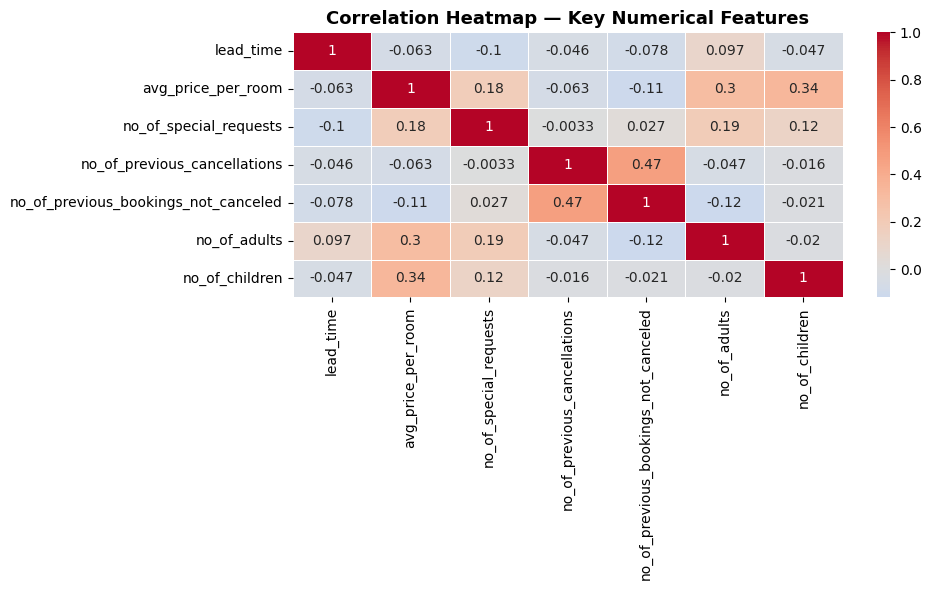

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select only important numerical features
important_num_cols = [
    'lead_time',
    'avg_price_per_room',
    'no_of_special_requests',
    'no_of_previous_cancellations',
    'no_of_previous_bookings_not_canceled',
    'no_of_adults',
    'no_of_children'
]

# Correlation heatmap
plt.figure(figsize=(10, 6))
corr = df[important_num_cols].corr()

sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, linewidths=0.4)
plt.title('Correlation Heatmap — Key Numerical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


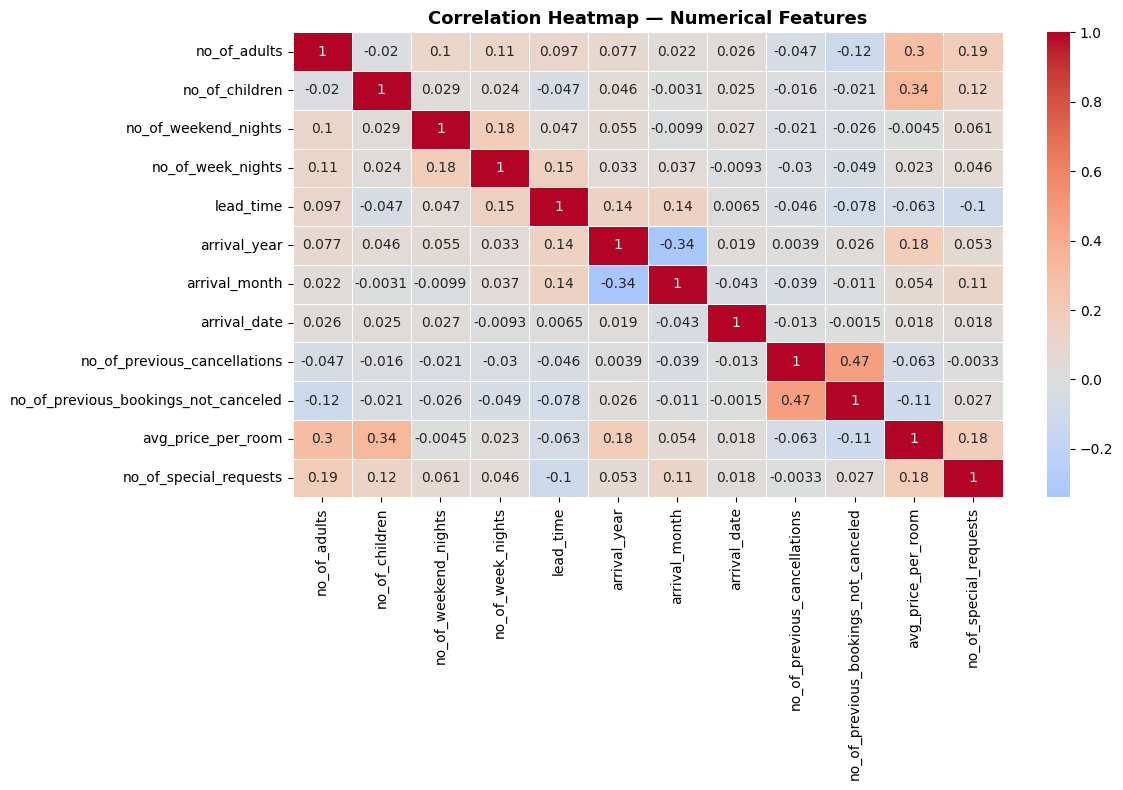

In [15]:
# Correlation heatmap among numerical features
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, linewidths=0.4)
plt.title('Correlation Heatmap — Numerical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


       Booking_ID  no_of_adults  no_of_children  no_of_weekend_nights  \
count       36275  36275.000000    36275.000000          36275.000000   
unique      36275           NaN             NaN                   NaN   
top      INN36275           NaN             NaN                   NaN   
freq            1           NaN             NaN                   NaN   
mean          NaN      1.844962        0.105279              0.810724   
std           NaN      0.518715        0.402648              0.870644   
min           NaN      0.000000        0.000000              0.000000   
25%           NaN      2.000000        0.000000              0.000000   
50%           NaN      2.000000        0.000000              1.000000   
75%           NaN      2.000000        0.000000              2.000000   
max           NaN      4.000000       10.000000              7.000000   

        no_of_week_nights type_of_meal_plan  required_car_parking_space  \
count        36275.000000             36275     

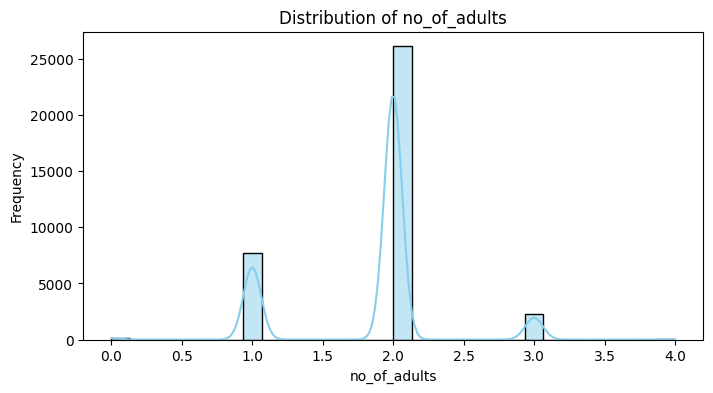

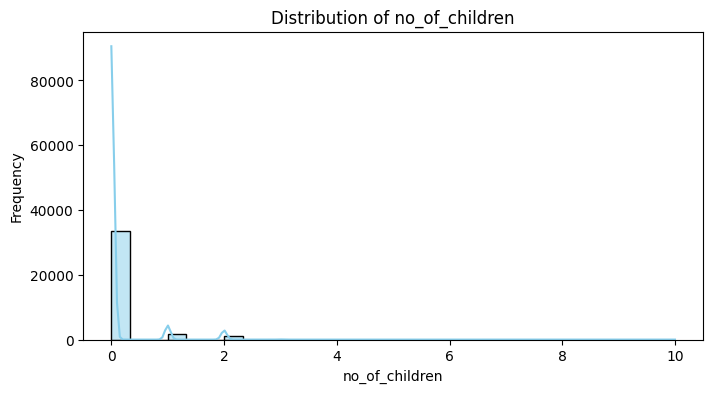

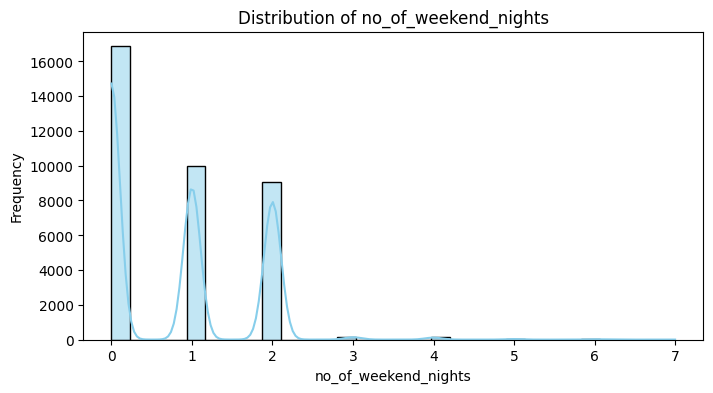

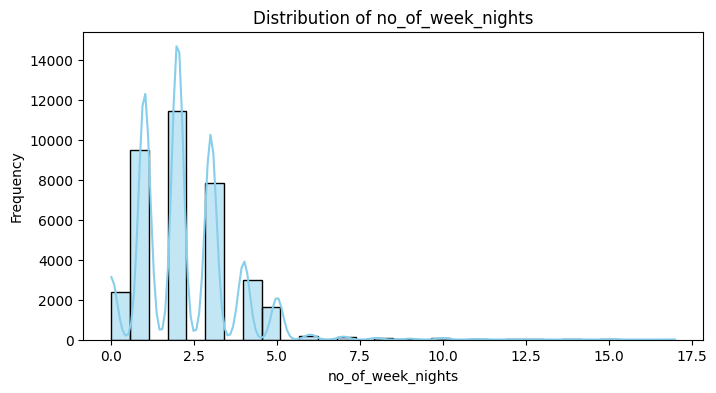

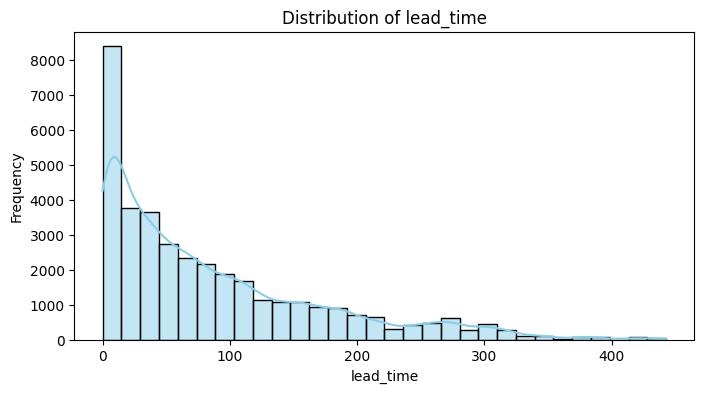

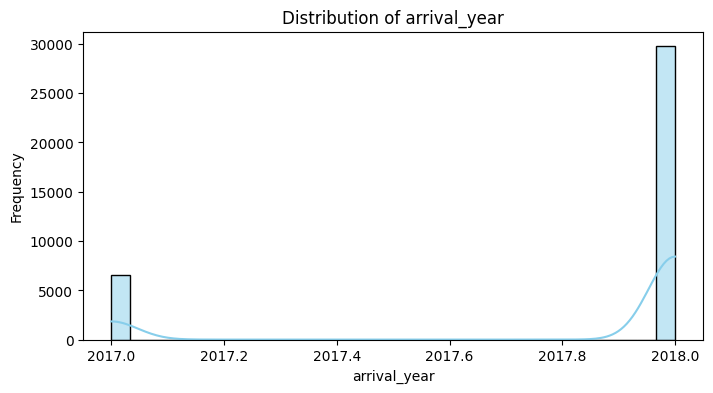

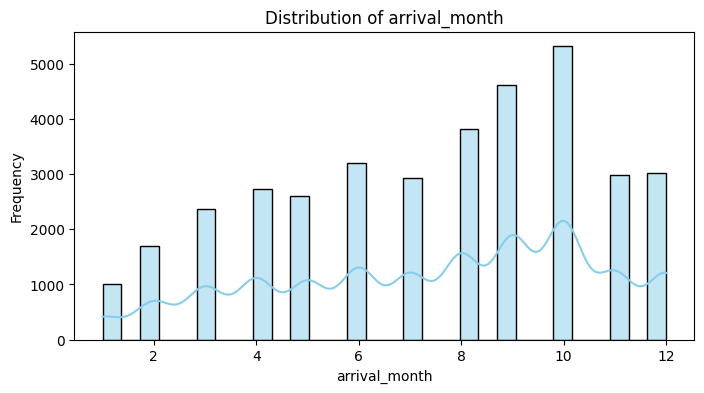

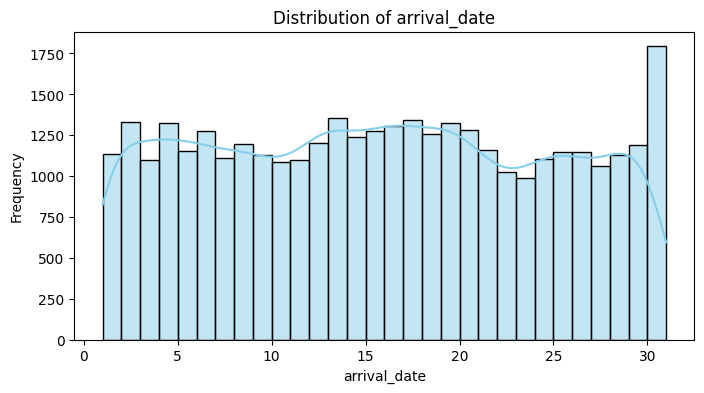

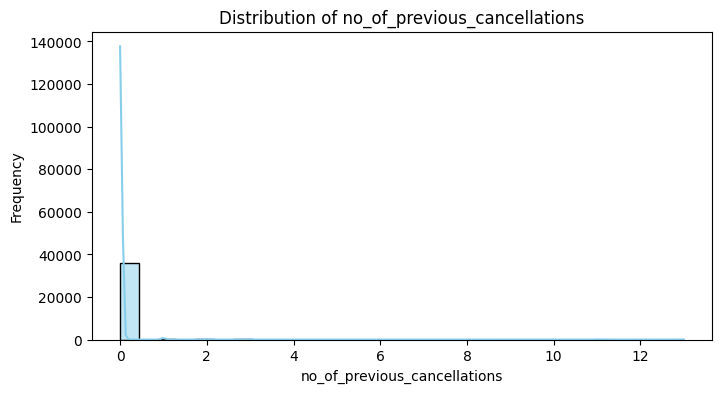

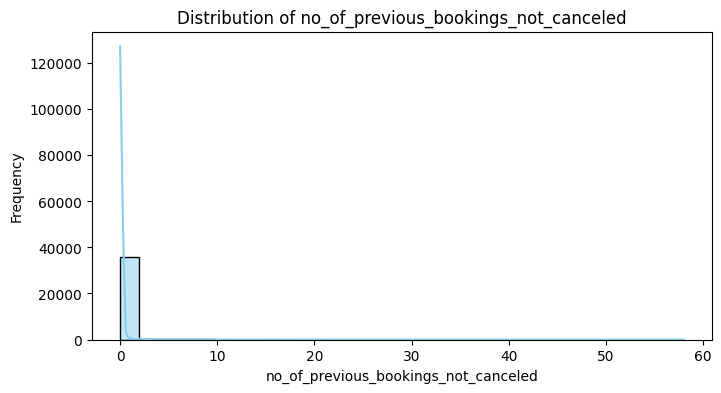

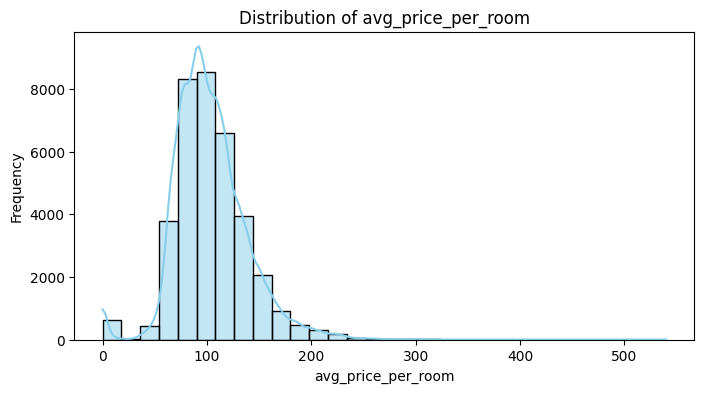

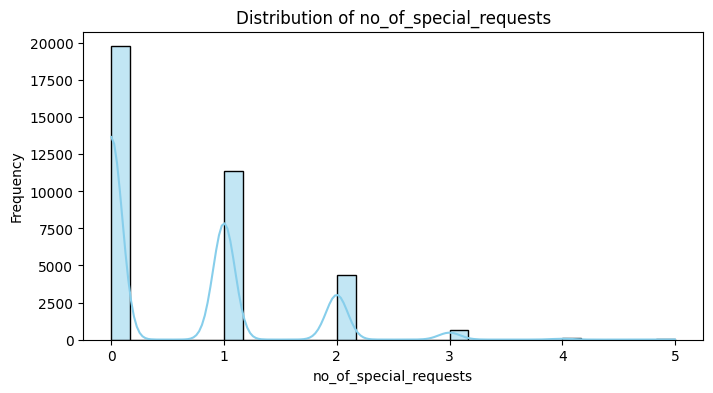

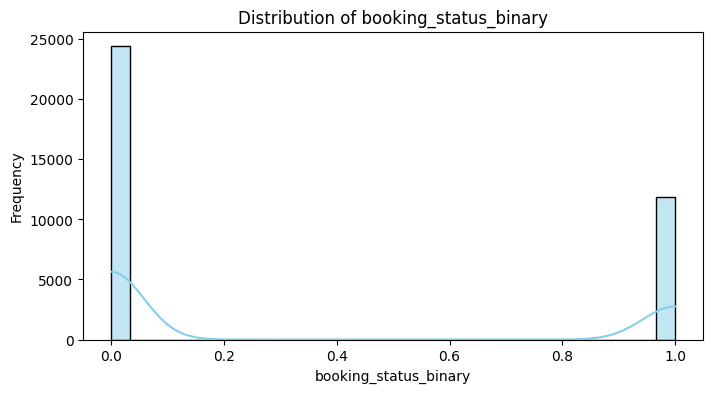

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Basic summary
print(df.describe(include='all'))

# Plot each numeric column separately, one below the other
num_cols = df.select_dtypes(include=['int64','float64']).columns

for col in num_cols:
    plt.figure(figsize=(8,4))
    sns.histplot(df[col], bins=30, kde=True, color='skyblue')
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()


In [9]:
cat_col_ = df.select_dtypes(include='object').columns.tolist()
cat_col_

['Booking_ID',
 'type_of_meal_plan',
 'required_car_parking_space',
 'room_type_reserved',
 'market_segment_type',
 'repeated_guest',
 'booking_status']

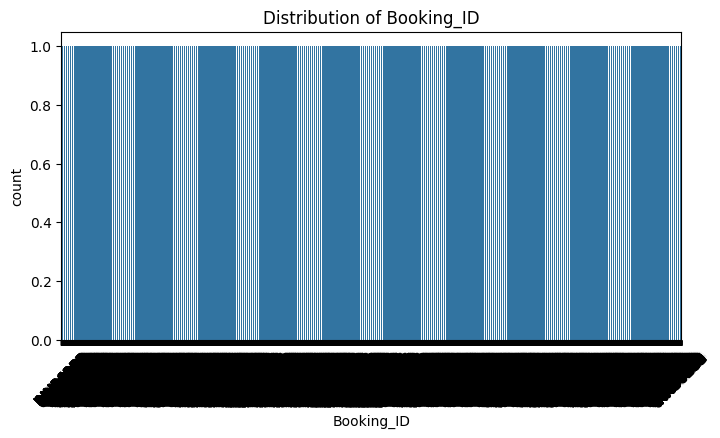

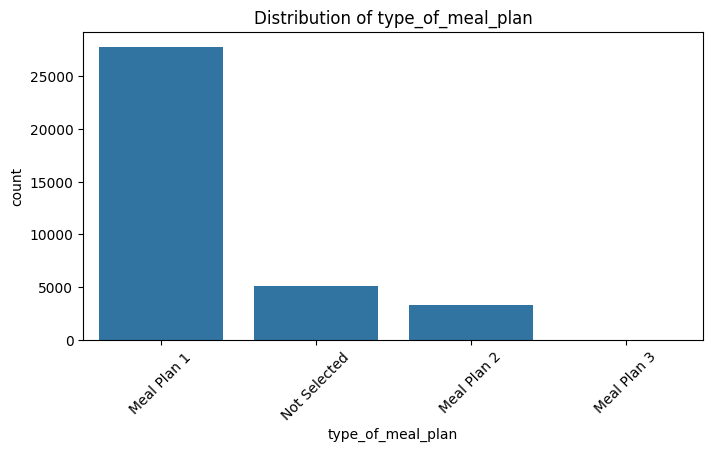

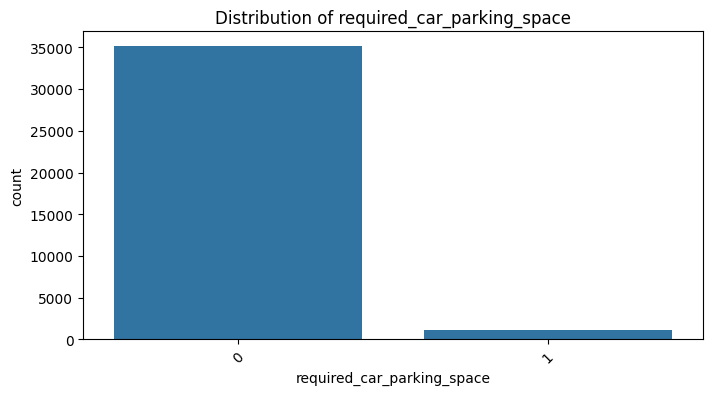

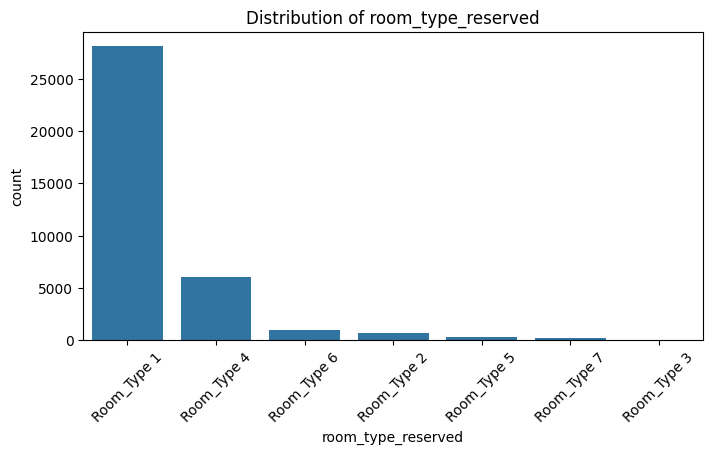

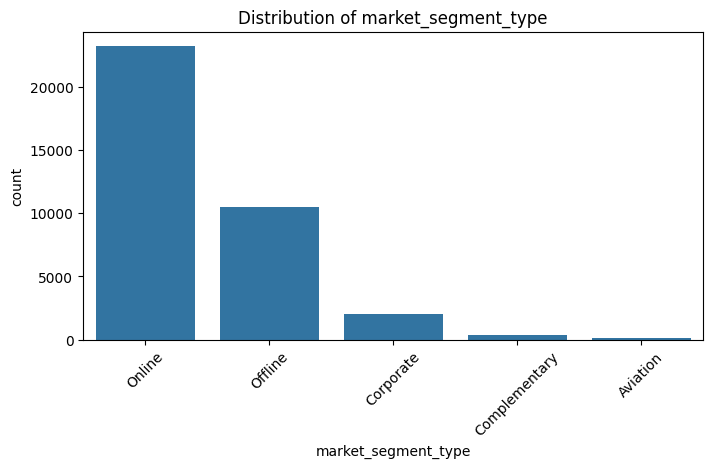

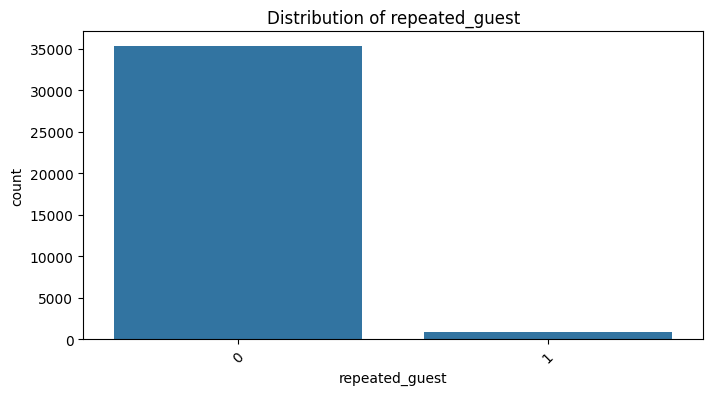

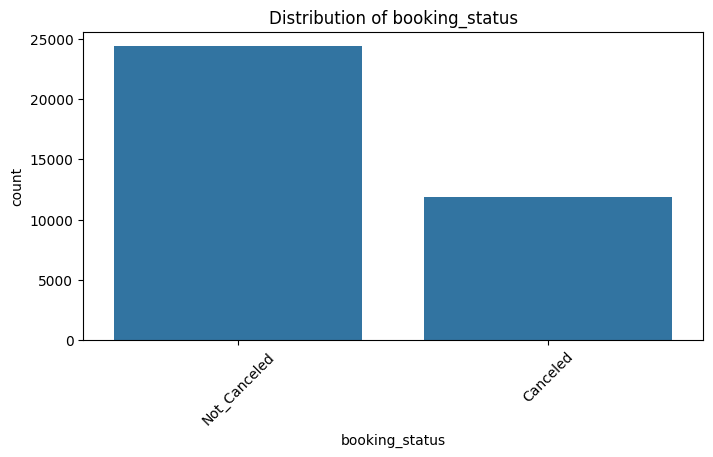

In [21]:
# Count plots for categorical columns
for col in cat_col_ :
    plt.figure(figsize=(8,4))
    sns.countplot(x=col, data=df, order=df[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()


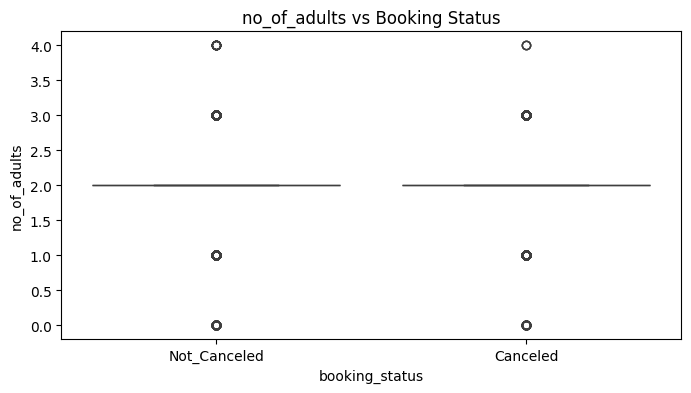

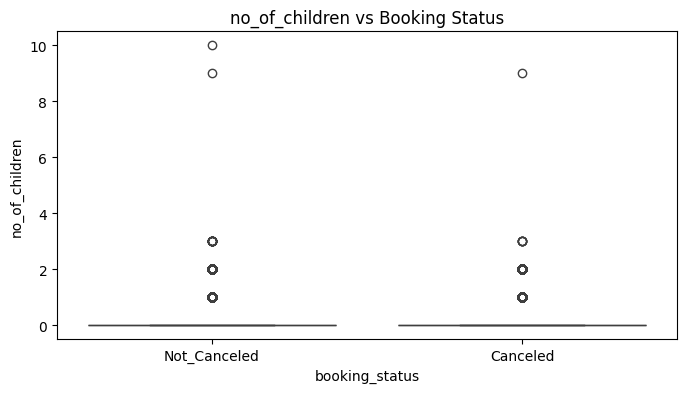

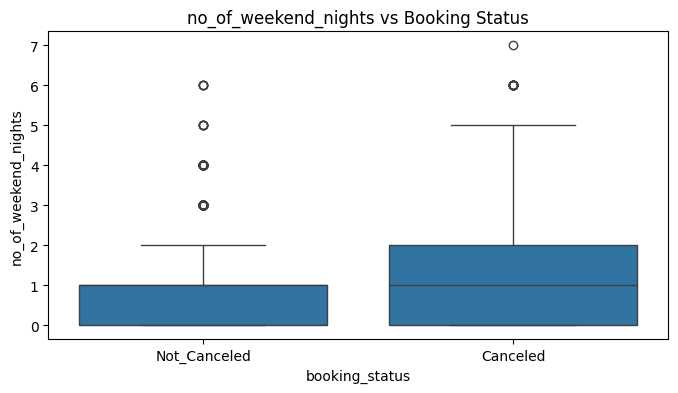

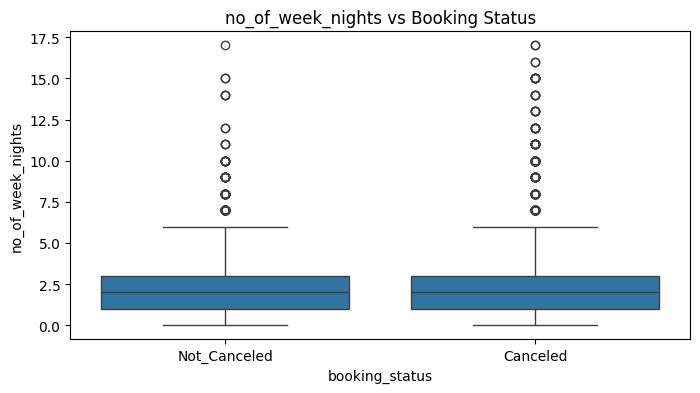

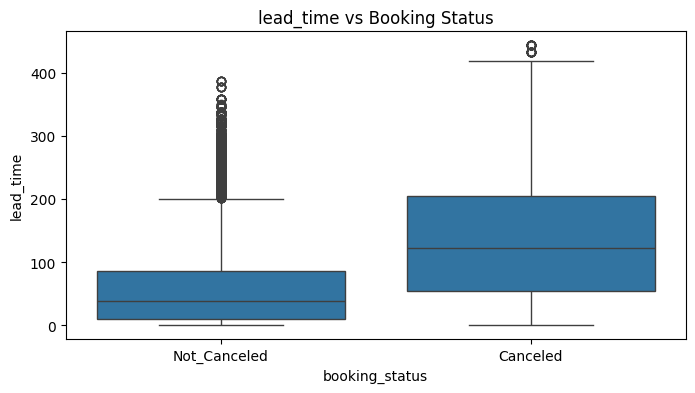

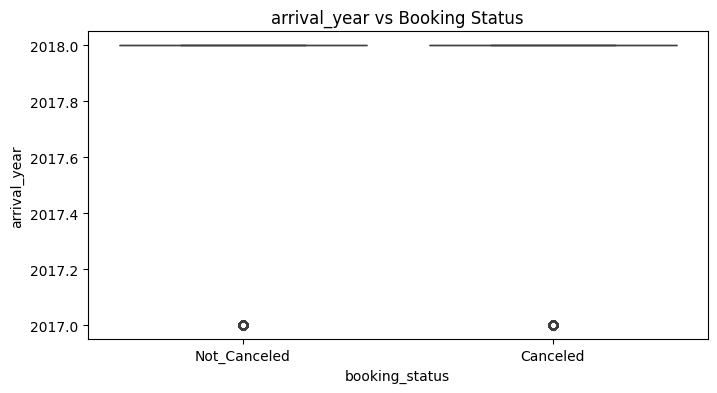

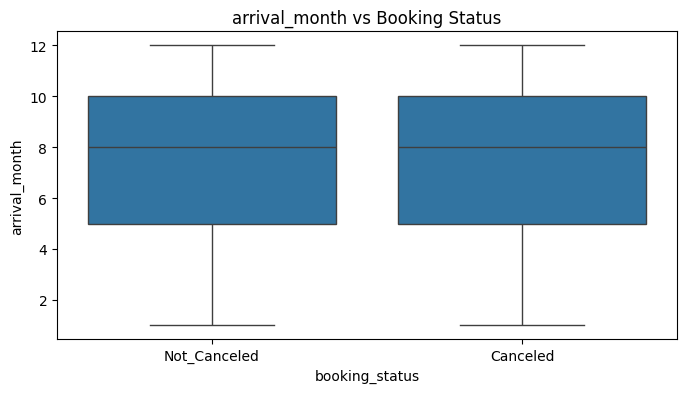

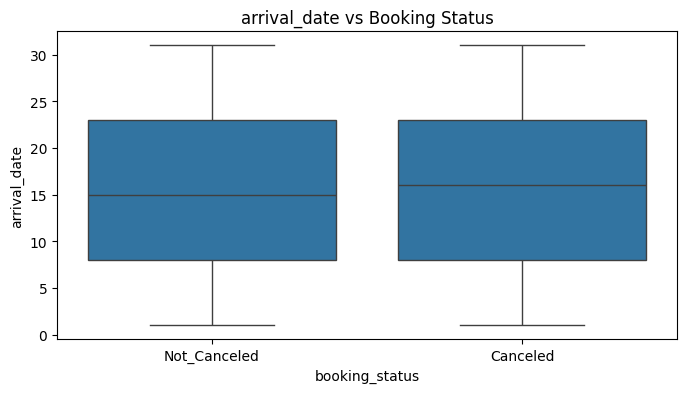

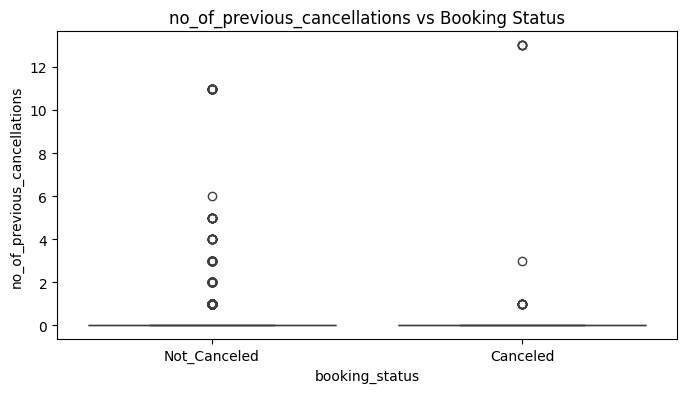

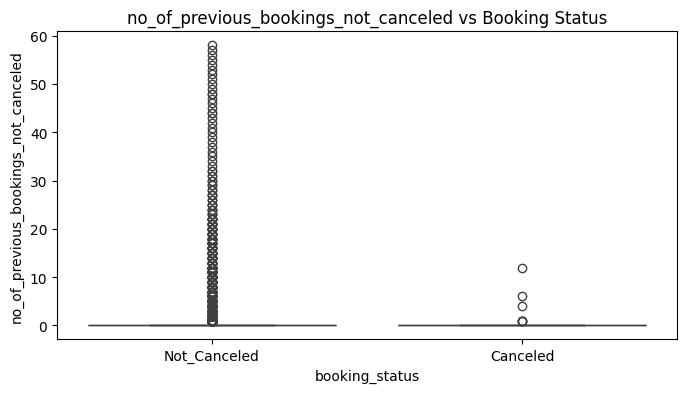

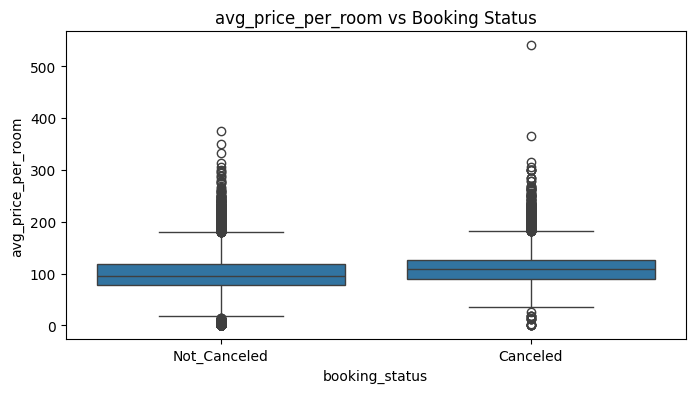

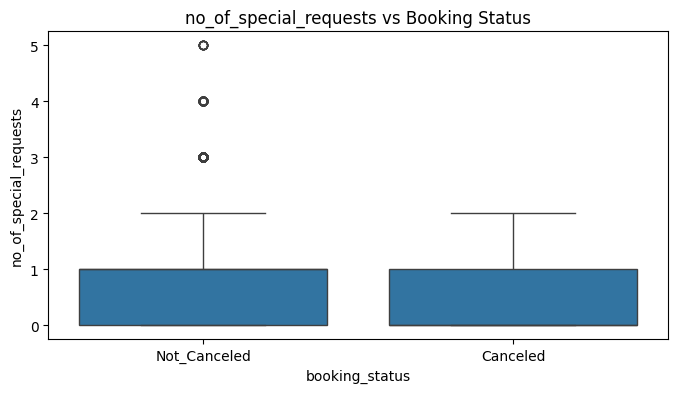

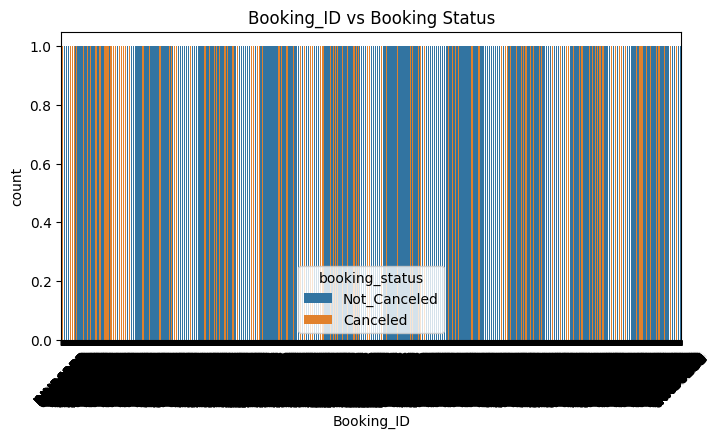

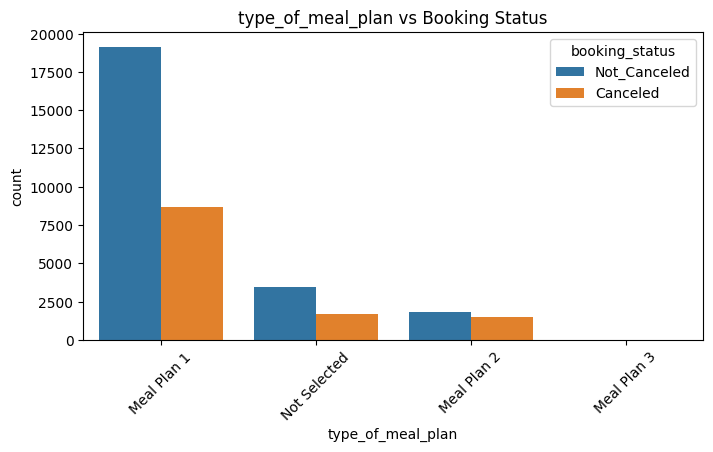

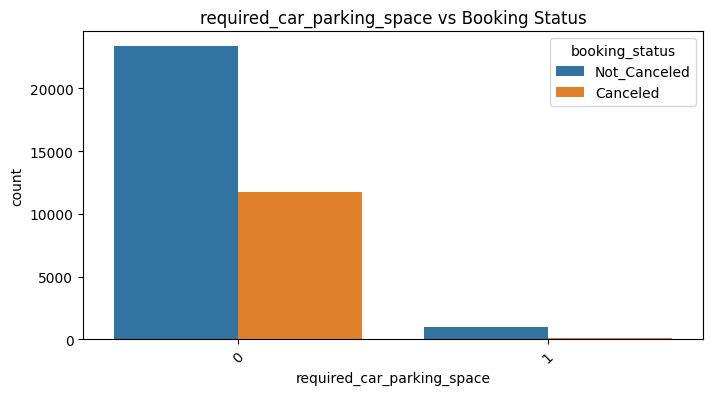

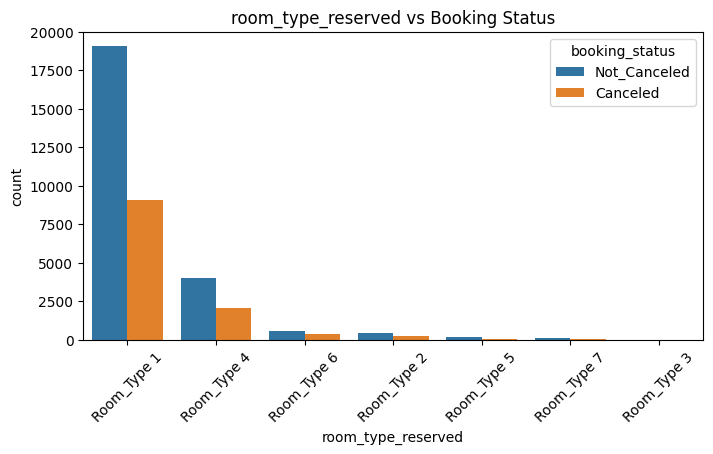

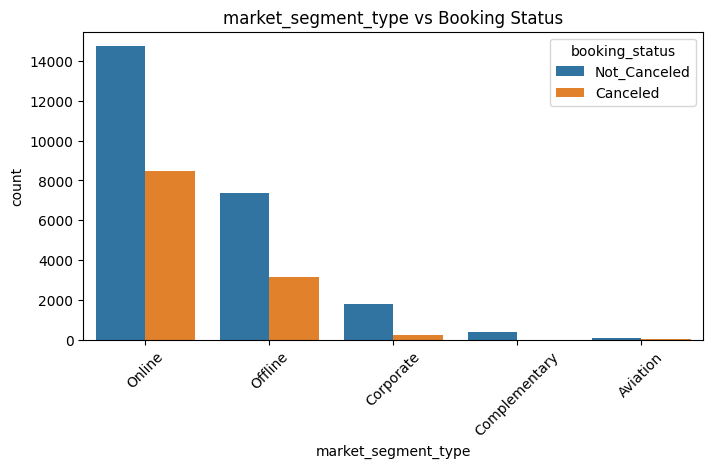

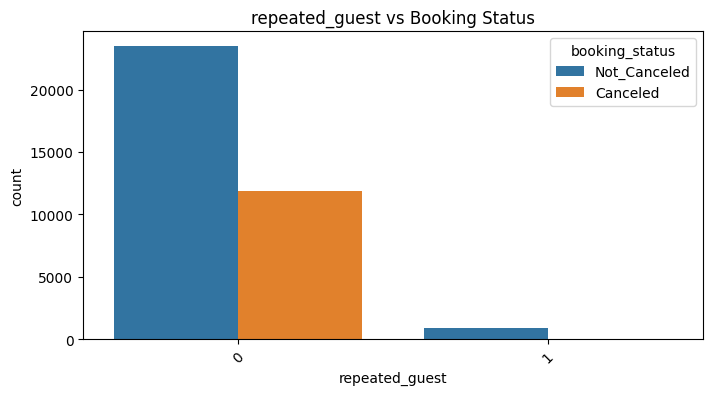

In [22]:
# Numeric vs Target
for col in df.select_dtypes(include=['int64','float64']).columns:
    plt.figure(figsize=(8,4))
    sns.boxplot(x='booking_status', y=col, data=df)
    plt.title(f"{col} vs Booking Status")
    plt.show()

# Categorical vs Target
for col in df.select_dtypes(include='object').columns:
    if col != 'booking_status':
        plt.figure(figsize=(8,4))
        sns.countplot(x=col, hue='booking_status', data=df,
                      order=df[col].value_counts().index)
        plt.title(f"{col} vs Booking Status")
        plt.xticks(rotation=45)
        plt.show()


In [10]:
df["booking_status"].value_counts()

booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64

In [41]:
import pandas as pd
from scipy.stats import pointbiserialr

# Encode target as binary (Canceled=1, Not_Canceled=0)
df['booking_status_binary'] = df['booking_status'].map({'Canceled':1, 'Not_Canceled':0})

num_cols = df.select_dtypes(include=['int64','float64']).columns.drop('booking_status_binary')

importance_num = {}
for col in num_cols:
    corr, pval = pointbiserialr(df[col], df['booking_status_binary'])
    importance_num[col] = {"correlation": corr, "p_value": pval}

# Sort by absolute correlation
importance_num = pd.DataFrame(importance_num).T.sort_values(by="correlation", key=abs, ascending=False)
print(importance_num)


                                      correlation        p_value
lead_time                                0.438538   0.000000e+00
no_of_special_requests                  -0.253070   0.000000e+00
arrival_year                             0.179529  2.085779e-260
avg_price_per_room                       0.142569  5.230319e-164
no_of_week_nights                        0.092996   1.727216e-70
no_of_adults                             0.086920   8.848338e-62
no_of_weekend_nights                     0.061563   8.340702e-32
no_of_previous_bookings_not_canceled    -0.060179   1.828736e-30
no_of_previous_cancellations            -0.033728   1.315207e-10
no_of_children                           0.033078   2.947637e-10
arrival_month                           -0.011233   3.239998e-02
arrival_date                             0.010629   4.292948e-02


In [12]:
from sklearn.preprocessing import LabelEncoder
from scipy.stats import chi2_contingency

cat_cols = df.select_dtypes(include='object').columns.drop(['booking_status'])

importance_cat = {}
for col in cat_cols:
    contingency = pd.crosstab(df[col], df['booking_status'])
    chi2, pval, dof, expected = chi2_contingency(contingency)
    importance_cat[col] = {"chi2_stat": chi2, "p_value": pval}

importance_cat = pd.DataFrame(importance_cat).T.sort_values(by="chi2_stat", ascending=False)
print(importance_cat)


                               chi2_stat        p_value
Booking_ID                  36275.000000   4.975315e-01
market_segment_type           814.108865  6.748763e-175
repeated_guest                416.095551   1.727050e-92
type_of_meal_plan             278.294909   4.951915e-60
required_car_parking_space    268.388467   2.547649e-60
room_type_reserved             57.334952   1.562780e-10


## Detect Multicolinearity

In [15]:
!pip install statsmodels

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.6 MB 1.1 MB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.6 MB 2.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.3/9.6 MB 2.4 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.6 MB 2.0 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/9.6 MB 2.0 MB/s eta 0:00:04
   --------- ------------------------------ 2.4/9.6 MB 2.0 MB/s eta 0:00:04
   ---------- ----------------------------- 2.6/9.6 MB 1.6 MB/s eta 0:00:05
   ------------- -------------------------- 3.1/9.6 MB 1.7 MB/s eta 0:00:04
   ------------------------ --------------- 5.8/9.6 MB 2.9 MB/s eta 0:00:02
   ----------------------------- ---------- 7.1/9.6 MB 3.3 MB/s eta 0:00:01
   ------------------------------------- -- 8.9/9.6 MB 3.7 MB/s eta 0:00:01
   -----------------------

In [16]:
# numerical columns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select numeric features
num_cols = df.select_dtypes(include=['int64','float64']).columns

# Add constant for VIF calculation
X_num = add_constant(df[num_cols])

vif_num = pd.DataFrame()
vif_num["Feature"] = X_num.columns
vif_num["VIF"] = [variance_inflation_factor(X_num.values, i) for i in range(X_num.shape[1])]

print("VIF for Numeric Features:")
print(vif_num.sort_values(by="VIF", ascending=False))


VIF for Numeric Features:
                                 Feature           VIF
0                                  const  3.527108e+07
13                 booking_status_binary  1.418144e+00
11                    avg_price_per_room  1.408716e+00
5                              lead_time  1.378860e+00
10  no_of_previous_bookings_not_canceled  1.319042e+00
9           no_of_previous_cancellations  1.284267e+00
6                           arrival_year  1.276219e+00
7                          arrival_month  1.236934e+00
12                no_of_special_requests  1.207100e+00
1                           no_of_adults  1.193979e+00
2                         no_of_children  1.164234e+00
4                      no_of_week_nights  1.065912e+00
3                   no_of_weekend_nights  1.052845e+00
8                           arrival_date  1.004772e+00


In [23]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

def calculate_vif(X):
    vif_data = pd.DataFrame()
    vif_data["Feature"] = X.columns
    vif_data["VIF"] = [
        1 / (1 - LinearRegression().fit(
            X.drop(col, axis=1), X[col]
        ).score(X.drop(col, axis=1), X[col]))
        for col in X.columns
    ]
    return vif_data.sort_values(by="VIF", ascending=False)


In [29]:
# Example: drop categories with < 50 occurrences
for col in cat_cols:
    counts = df[col].value_counts()
    rare = counts[counts < 50].index
    df[col] = df[col].replace(rare, "Other")



In [30]:
selected_cat_cols = ['market_segment_type','room_type_reserved','type_of_meal_plan']
X_cat = pd.get_dummies(df[selected_cat_cols], drop_first=True)
vif_cat = calculate_vif(X_cat)
print(vif_cat)


                              Feature         VIF
4      room_type_reserved_Room_Type 1  903.920709
6      room_type_reserved_Room_Type 4  723.036859
8      room_type_reserved_Room_Type 6  135.563034
5      room_type_reserved_Room_Type 2   98.119292
3          market_segment_type_Online   67.451507
2         market_segment_type_Offline   60.967014
7      room_type_reserved_Room_Type 5   38.614567
9      room_type_reserved_Room_Type 7   23.490862
1       market_segment_type_Corporate   16.286369
0   market_segment_type_Complementary    4.131192
11     type_of_meal_plan_Not Selected    1.187030
10      type_of_meal_plan_Meal Plan 2    1.105833
12            type_of_meal_plan_Other    1.017244


##  Data Cleaning & Preprocessing -- Drop Uninformative ID Columns

In [46]:
if 'Booking_ID' in df.columns:
    df = df.drop(columns=['Booking_ID'])
print("Columns after dropping ID:", df.shape[1])


Columns after dropping ID: 18


### Outlier Treatment — IQR Capping (Winsorization)

In [22]:
import pandas as pd

def detect_outliers(df, k=1.5):
    outlier_counts = {}
    total_outliers = 0
    
    # Loop through all numeric columns
    for col in df.select_dtypes(include=['number']).columns:
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - k * iqr, q3 + k * iqr
        
        mask = (df[col] < lower) | (df[col] > upper)
        n_outliers = mask.sum()
        
        outlier_counts[col] = {
            "outliers": n_outliers,
            "lower_bound": lower,
            "upper_bound": upper
        }
        total_outliers += n_outliers
    
    return outlier_counts, total_outliers

# Example usage
outlier_summary, total_outliers = detect_outliers(df)

# Print results
for col, stats in outlier_summary.items():
    print(f"{col}: {stats['outliers']} outliers "
          f"(bounds [{stats['lower_bound']:.2f}, {stats['upper_bound']:.2f}])")

print(f"\nTotal outliers across dataset: {total_outliers}")


no_of_adults: 10167 outliers (bounds [2.00, 2.00])
no_of_children: 2698 outliers (bounds [0.00, 0.00])
no_of_weekend_nights: 21 outliers (bounds [-3.00, 5.00])
no_of_week_nights: 324 outliers (bounds [-2.00, 6.00])
required_car_parking_space: 1124 outliers (bounds [0.00, 0.00])
lead_time: 1331 outliers (bounds [-146.50, 289.50])
arrival_year: 6514 outliers (bounds [2018.00, 2018.00])
arrival_month: 0 outliers (bounds [-2.50, 17.50])
arrival_date: 0 outliers (bounds [-14.50, 45.50])
repeated_guest: 930 outliers (bounds [0.00, 0.00])
no_of_previous_cancellations: 338 outliers (bounds [0.00, 0.00])
no_of_previous_bookings_not_canceled: 812 outliers (bounds [0.00, 0.00])
avg_price_per_room: 1696 outliers (bounds [20.75, 179.55])
no_of_special_requests: 761 outliers (bounds [-1.50, 2.50])

Total outliers across dataset: 26716


In [42]:
def iqr_cap(series, k=1.5, min_value=None):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    
    # enforce minimum valid value if provided
    if min_value is not None:
        lower = max(lower, min_value)
    
    capped_series = series.clip(lower=lower, upper=upper)
    
    # count how many values were capped
    capped_low = (series < lower).sum()
    capped_high = (series > upper).sum()
    
    return capped_series, lower, upper, capped_low, capped_high

outlier_cols = ['lead_time', 'avg_price_per_room']

for col in outlier_cols:
    before_min, before_max = df[col].min(), df[col].max()
    df[col], lo, hi, capped_low, capped_high = iqr_cap(df[col], min_value=0 if col=='lead_time' else None)
    
    print(f"{col}: capped to [{lo:.2f}, {hi:.2f}] "
          f"(raw range was [{before_min:.2f}, {before_max:.2f}])")
    print(f"   → {capped_low} values capped at lower bound, {capped_high} values capped at upper bound\n")


lead_time: capped to [0.00, 289.50] (raw range was [0.00, 443.00])
   → 0 values capped at lower bound, 1331 values capped at upper bound

avg_price_per_room: capped to [20.75, 179.55] (raw range was [0.00, 540.00])
   → 627 values capped at lower bound, 1069 values capped at upper bound



In [55]:
# Separate numeric columns
num_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()

# Calculate skewness for each numeric column
skew_values = df[num_cols].skew()

# Display nicely
print("Skewness of Numeric Columns:\n")
for col, val in skew_values.items():
    print(f"{col}: {val:.2f}")


Skewness of Numeric Columns:

no_of_adults: -0.33
no_of_children: 4.71
no_of_weekend_nights: 0.74
no_of_week_nights: 1.60
lead_time: 1.07
arrival_year: -1.67
arrival_month: -0.35
arrival_date: 0.03
no_of_previous_cancellations: 25.20
no_of_previous_bookings_not_canceled: 19.25
avg_price_per_room: 0.35
no_of_special_requests: 1.15
booking_status: 0.73


###  Encode the Target Variable

In [47]:
df['booking_status'] = df['booking_status'].map({'Not_Canceled': 0, 'Canceled': 1})
df['booking_status'].value_counts()


booking_status
0    24390
1    11885
Name: count, dtype: int64

## Feature Target Split

In [43]:
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status,booking_status_binary
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224.0,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled,0
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5.0,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled,0
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1.0,2018,2,28,Online,0,0,0,60.00,0,Canceled,1
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211.0,2018,5,20,Online,0,0,0,100.00,0,Canceled,1
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48.0,2018,4,11,Online,0,0,0,94.50,0,Canceled,1


In [45]:
df = df.drop(columns = ["booking_status_binary"])
df.shape

(36275, 19)

In [49]:
print(df.shape)
df.head()

(36275, 18)


,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,1,2,Meal Plan 1,0,Room_Type 1,224.0,2017,10,2,Offline,0,0,0,65.00,0,0
1,2,0,2,3,Not Selected,0,Room_Type 1,5.0,2018,11,6,Online,0,0,0,106.68,1,0
2,1,0,2,1,Meal Plan 1,0,Room_Type 1,1.0,2018,2,28,Online,0,0,0,60.00,0,1
3,2,0,0,2,Meal Plan 1,0,Room_Type 1,211.0,2018,5,20,Online,0,0,0,100.00,0,1
4,2,0,1,1,Not Selected,0,Room_Type 1,48.0,2018,4,11,Online,0,0,0,94.50,0,1


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 18 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          36275 non-null  int64  
 1   no_of_children                        36275 non-null  int64  
 2   no_of_weekend_nights                  36275 non-null  int64  
 3   no_of_week_nights                     36275 non-null  int64  
 4   type_of_meal_plan                     36275 non-null  object 
 5   required_car_parking_space            36275 non-null  object 
 6   room_type_reserved                    36275 non-null  object 
 7   lead_time                             36275 non-null  float64
 8   arrival_year                          36275 non-null  int64  
 9   arrival_month                         36275 non-null  int64  
 10  arrival_date                          36275 non-null  int64  
 11  market_segment_

In [52]:
# separating the input and output feature
X = df.drop(columns=['booking_status'])
y = df['booking_status']

# Separate numeric and categorical columns
numeric_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)


Categorical columns: ['type_of_meal_plan', 'required_car_parking_space', 'room_type_reserved', 'market_segment_type', 'repeated_guest']
Numeric columns: ['no_of_adults', 'no_of_children', 'no_of_weekend_nights', 'no_of_week_nights', 'lead_time', 'arrival_year', 'arrival_month', 'arrival_date', 'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled', 'avg_price_per_room', 'no_of_special_requests', 'booking_status']


In [60]:
#  Group columns by how they should be transformed

# Highly skewed (skew > 0.75) -> log1p to shrink the long tail, then scale
skewed_cols = [
    'no_of_children',                        # skew 4.71
    'no_of_previous_cancellations',          # skew 25.20
    'no_of_previous_bookings_not_canceled',  # skew 19.25
    'no_of_week_nights',                     # skew 1.60
    'no_of_special_requests',                # skew 1.15
    'lead_time',                             # skew 1.07
    'no_of_weekend_nights',                  # skew 0.74
]

# Roughly symmetric (|skew| < 0.5) -> scale only, no reshaping needed
normal_cols = [
    'no_of_adults',        # skew -0.33
    'arrival_month',       # skew -0.35
    'arrival_date',        # skew 0.03
    'avg_price_per_room',  # skew 0.35
]

# Only 2 unique values -> behaves like a category, not a continuous number
low_cardinality_numeric = ['arrival_year']

# True categorical / binary-flag columns -> one-hot encode
categorical_cols = [
    'type_of_meal_plan',
    'required_car_parking_space',
    'room_type_reserved',
    'market_segment_type',
    'repeated_guest',
] + low_cardinality_numeric

### 3.5 Train/Test Split (Stratified, 80/20)

In [62]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True).round(3))
print("Test class balance:\n", y_test.value_counts(normalize=True).round(3))


Train shape: (29020, 17)  Test shape: (7255, 17)
Train class balance:
 booking_status
0    0.672
1    0.328
Name: proportion, dtype: float64
Test class balance:
 booking_status
0    0.672
1    0.328
Name: proportion, dtype: float64


###  Preprocessing Pipeline: One-Hot Encoding + Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 4. Build a small pipeline per column group
skewed_pipeline = Pipeline(steps=[
    ('log1p', FunctionTransformer(np.log1p, validate=False)),  # shrink long tail
    ('scale', StandardScaler()),                                # put on common scale
])

normal_pipeline = Pipeline(steps=[
    ('scale', StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore')),
])


In [ ]:
# 5. Combine everything into one ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('skewed', skewed_pipeline, skewed_cols),
    ('normal', normal_pipeline, normal_cols),
    ('cat', categorical_pipeline, categorical_cols),
])


In [66]:
#  Fit ONLY on training data, then transform both sets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()
    X_test_processed = X_test_processed.toarray()

print("Train shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (29020, 27)
Test shape: (7255, 27)


## 4. ANN Model Architecture & Construction

In [ ]:
n_features = X_train_processed.shape[1]

model = keras.Sequential([
    layers.Input(shape=(n_features,), name='input_layer'),

    layers.Dense(64, activation='relu', name='hidden_1'),
    layers.Dropout(0.2, name='dropout_1'),

    layers.Dense(32, activation='relu', name='hidden_2'),
    layers.Dropout(0.2, name='dropout_2'),

    layers.Dense(16, activation='relu', name='hidden_3'),

    layers.Dense(1, activation='sigmoid', name='output_layer')
], name='hotel_cancellation_ann')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

model.summary()

Model: "hotel_cancellation_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                │ (None, 64)             │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_3 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,417 (17.25 KB)

 Trainable params: 4,417 (17.25 KB)

 Non-trainable params: 0 (0.00 B)

## Handling class imbalance using class_weight

In [69]:
from sklearn.utils.class_weight import compute_class_weight

# Compute weights that are inversely proportional to class frequency
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {i: w for i, w in enumerate(class_weights_array)}

print("Class weights:", class_weight_dict)
# Expect something like {0: 0.74, 1: 1.53}
# Class 1 (Canceled) gets a higher weight since it's the minority class

Class weights: {0: np.float64(0.7436449364493645), 1: np.float64(1.5260832982751367)}


##  Model Training & Optimization

In [70]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_processed, y_train.values,
    validation_split=0.2,
    epochs=100,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7297 - loss: 0.5369 - precision: 0.5689 - recall: 0.7336 - val_accuracy: 0.8007 - val_loss: 0.4433 - val_precision: 0.6698 - val_recall: 0.7572
Epoch 2/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7807 - loss: 0.4720 - precision: 0.6382 - recall: 0.7684 - val_accuracy: 0.8117 - val_loss: 0.4244 - val_precision: 0.6832 - val_recall: 0.7796
Epoch 3/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7895 - loss: 0.4539 - precision: 0.6509 - recall: 0.7750 - val_accuracy: 0.8196 - val_loss: 0.4157 - val_precision: 0.6961 - val_recall: 0.7854
Epoch 4/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7985 - loss: 0.4385 - precision: 0.6668 - recall: 0.7735 - val_accuracy: 0.8253 - val_loss: 0.4072 - val_precision: 0.7030 - val_recall: 0.7966
Epoch 5/100
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8014 - loss: 0.4323 - precision: 0.6696 - recall: 0.7813 - val_accuracy: 0.8262 - val_los

## Evaluation & Analytics

###  Training Curves


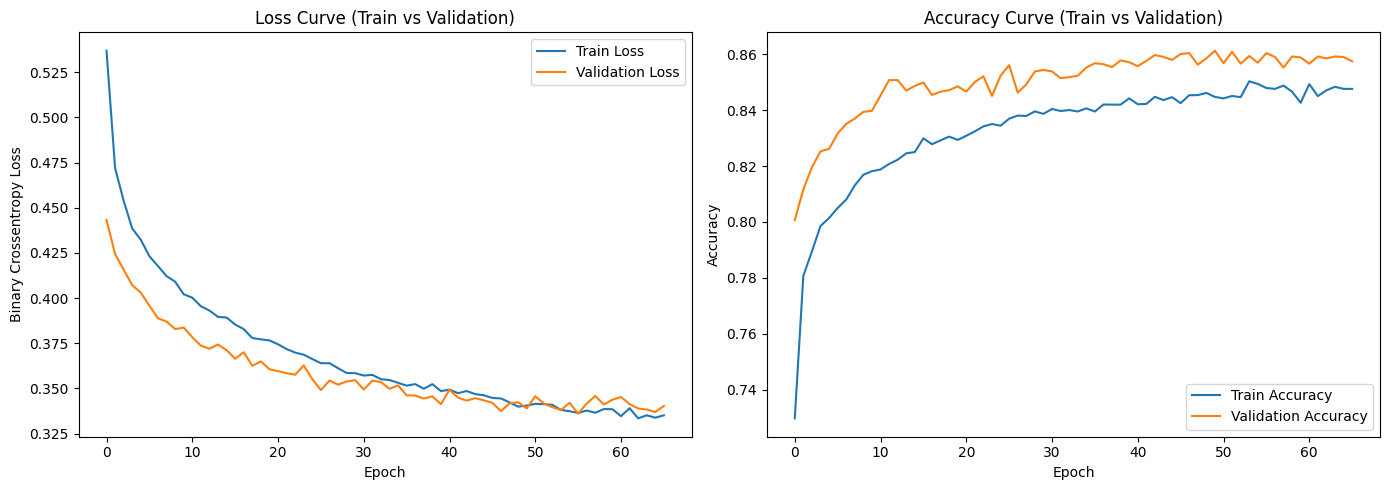

In [71]:
hist_df = pd.DataFrame(history.history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_df['loss'], label='Train Loss')
axes[0].plot(hist_df['val_loss'], label='Validation Loss')
axes[0].set_title('Loss Curve (Train vs Validation)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Crossentropy Loss')
axes[0].legend()

axes[1].plot(hist_df['accuracy'], label='Train Accuracy')
axes[1].plot(hist_df['val_accuracy'], label='Validation Accuracy')
axes[1].set_title('Accuracy Curve (Train vs Validation)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import accuracy_score, log_loss


y_train_pred_proba = model.predict(X_train_processed).ravel()
y_test_pred_proba  = model.predict(X_test_processed).ravel()

y_train_pred = (y_train_pred_proba >= 0.5).astype(int)
y_test_pred  = (y_test_pred_proba  >= 0.5).astype(int)


train_accuracy = accuracy_score(y_train.values, y_train_pred)
test_accuracy  = accuracy_score(y_test.values,  y_test_pred)

train_error = 1 - train_accuracy
test_error  = 1 - test_accuracy


train_loss = log_loss(y_train.values, y_train_pred_proba)
test_loss  = log_loss(y_test.values,  y_test_pred_proba)

#  Print a clean comparison table

print(f"{'Metric':<20}{'Train':>10}{'Test':>10}{'Gap':>10}")
print("-" * 50)
print(f"{'Accuracy':<20}{train_accuracy:>10.4f}{test_accuracy:>10.4f}{test_accuracy - train_accuracy:>10.4f}")
print(f"{'Error (1-Acc)':<20}{train_error:>10.4f}{test_error:>10.4f}{test_error - train_error:>10.4f}")
print(f"{'Loss (BCE)':<20}{train_loss:>10.4f}{test_loss:>10.4f}{test_loss - train_loss:>10.4f}")


error_gap = test_error - train_error


907/907 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 834us/step
Metric                   Train      Test       Gap
--------------------------------------------------
Accuracy                0.8671    0.8612   -0.0059
Error (1-Acc)           0.1329    0.1388    0.0059
Loss (BCE)              0.3062    0.3190    0.0128

--- Interpretation ---
Train error and test error are close, and both are reasonably low.
→ This suggests a GOOD FIT: the model's complexity matches the
  amount of information in the data reasonably well.


### Test Set Performance

In [74]:
y_pred_proba = model.predict(X_test_processed).ravel()
y_pred = (y_pred_proba >= 0.5).astype(int)

test_accuracy  = accuracy_score(y_test.values, y_pred)
test_precision = precision_score(y_test.values, y_pred)
test_recall    = recall_score(y_test.values, y_pred)
test_f1        = f1_score(y_test.values, y_pred)
test_auc       = roc_auc_score(y_test.values, y_pred_proba)

print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall   : {test_recall:.4f}")
print(f"Test F1-score : {test_f1:.4f}")
print(f"Test ROC-AUC  : {test_auc:.4f}")
print()
print(classification_report(y_test.values, y_pred, target_names=['Not_Canceled', 'Canceled']))

227/227 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Test Accuracy : 0.8612
Test Precision: 0.7591
Test Recall   : 0.8443
Test F1-score : 0.7994
Test ROC-AUC  : 0.9356

              precision    recall  f1-score   support

Not_Canceled       0.92      0.87      0.89      4878
    Canceled       0.76      0.84      0.80      2377

    accuracy                           0.86      7255
   macro avg       0.84      0.86      0.85      7255
weighted avg       0.87      0.86      0.86      7255



### 6.3 Confusion Matrix


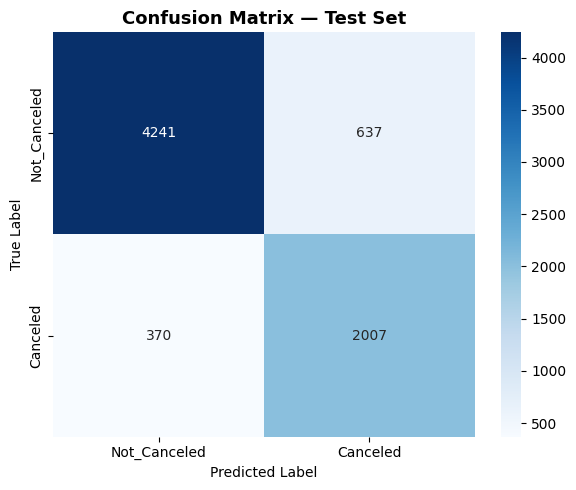

In [75]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not_Canceled', 'Canceled'],
            yticklabels=['Not_Canceled', 'Canceled'])
plt.title('Confusion Matrix — Test Set', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()


##  Hyperparameter Tuning with Optuna

In [31]:
!pip install optuna

  Using cached optuna-4.9.0-py3-none-any.whl.metadata (15 kB)
  Using cached sqlalchemy-2.0.51-cp310-cp310-win_amd64.whl.metadata (9.8 kB)
  Using cached tqdm-4.70.0-py3-none-any.whl.metadata (57 kB)
Using cached optuna-4.9.0-py3-none-any.whl (425 kB)
Using cached sqlalchemy-2.0.51-cp310-cp310-win_amd64.whl (2.1 MB)
Using cached tqdm-4.70.0-py3-none-any.whl (80 kB)

   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ---------------------------------------- 0/7 [tqdm]
   ----- ---------------------------------- 1/7 [Mako]
   ----- -----------------

In [ ]:

import optuna
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Search space
    units_1 = trial.suggest_categorical('units_1', [32, 64, 128])
    units_2 = trial.suggest_categorical('units_2', [16, 32, 64])
    units_3 = trial.suggest_categorical('units_3', [8, 16, 32])
    dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5)
    learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])

    trial_model = build_model(
        input_dim=n_features,
        units=(units_1, units_2, units_3),
        dropout_rate=dropout_rate,
        learning_rate=learning_rate
    )

    es = callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

    trial_history = trial_model.fit(
        X_train_processed, y_train.values,
        validation_split=0.2,
        epochs=30,
        batch_size=batch_size,
        callbacks=[es],
        verbose=0
    )

    val_loss = min(trial_history.history['val_loss'])
    return val_loss

study = optuna.create_study(direction='minimize', sampler=TPESampler(seed=SEED))
study.optimize(objective, n_trials=25, show_progress_bar=True)

print("Best trial:")
print("  Value (val_loss):", study.best_trial.value)
print("  Params:")
for k, v in study.best_trial.params.items():
    print(f"    {k}: {v}")

  0%|          | 0/25 [00:00<?, ?it/s]

Best trial:
  Value (val_loss): 0.29723286628723145
  Params:
    units_1: 128
    units_2: 64
    units_3: 16
    dropout_rate: 0.13095187307849335
    learning_rate: 0.0044784893397854676
    batch_size: 128


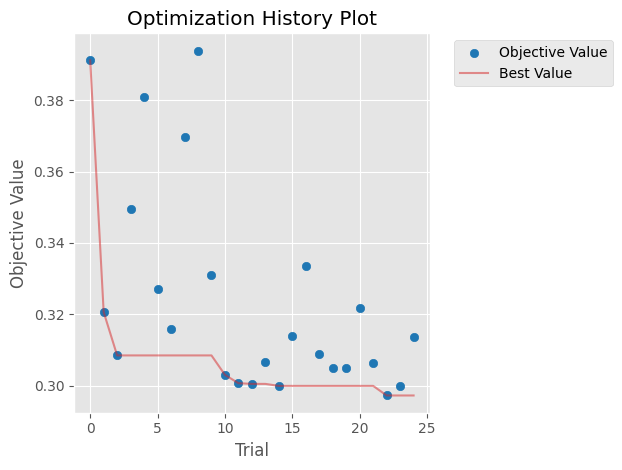

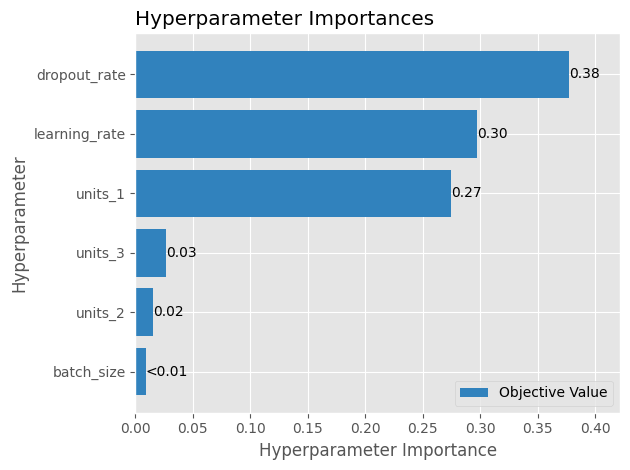

In [77]:
# Optuna optimization history & parameter importance
fig1 = optuna.visualization.matplotlib.plot_optimization_history(study)
plt.tight_layout()
plt.show()

fig2 = optuna.visualization.matplotlib.plot_param_importances(study)
plt.tight_layout()
plt.show()


###  Retrain Final Model with Best Hyperparameters

In [78]:
best_params = study.best_trial.params

best_model = build_model(
    input_dim=n_features,
    units=(best_params['units_1'], best_params['units_2'], best_params['units_3']),
    dropout_rate=best_params['dropout_rate'],
    learning_rate=best_params['learning_rate']
)

best_early_stop = callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
)

best_history = best_model.fit(
    X_train_processed, y_train.values,
    validation_split=0.2,
    epochs=100,
    batch_size=best_params['batch_size'],
    class_weight=class_weight_dict,
    callbacks=[best_early_stop],
    verbose=1
)

# Evaluate tuned model on test set
y_pred_proba_best = best_model.predict(X_test_processed).ravel()
y_pred_best = (y_pred_proba_best >= 0.5).astype(int)

print("Tuned Model — Test Set Performance")
print(f"Accuracy : {accuracy_score(y_test.values, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test.values, y_pred_best):.4f}")
print(f"Recall   : {recall_score(y_test.values, y_pred_best):.4f}")
print(f"F1-score : {f1_score(y_test.values, y_pred_best):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test.values, y_pred_proba_best):.4f}")

Epoch 1/100
182/182 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7749 - loss: 0.4682 - precision: 0.6278 - recall: 0.7738 - val_accuracy: 0.8272 - val_loss: 0.3887 - val_precision: 0.7217 - val_recall: 0.7583
Epoch 2/100
182/182 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8083 - loss: 0.4196 - precision: 0.6781 - recall: 0.7934 - val_accuracy: 0.8406 - val_loss: 0.3753 - val_precision: 0.7422 - val_recall: 0.7774
Epoch 3/100
182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8191 - loss: 0.4012 - precision: 0.6953 - recall: 0.8003 - val_accuracy: 0.8479 - val_loss: 0.3725 - val_precision: 0.7516 - val_recall: 0.7913
Epoch 4/100
182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8231 - loss: 0.3904 - precision: 0.7019 - recall: 0.8025 - val_accuracy: 0.8530 - val_loss: 0.3573 - val_precision: 0.7600 - val_recall: 0.7977
Epoch 5/100
182/182 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8288 - loss: 0.3776 - precision: 0.7095 - recall: 0.8113 - val_accuracy: 0.8546 - val_los

##  Results and Insights

In [79]:
results_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Baseline ANN': [
        test_accuracy, test_precision, test_recall, test_f1, test_auc
    ],
    'Optuna-Tuned ANN': [
        accuracy_score(y_test.values, y_pred_best),
        precision_score(y_test.values, y_pred_best),
        recall_score(y_test.values, y_pred_best),
        f1_score(y_test.values, y_pred_best),
        roc_auc_score(y_test.values, y_pred_proba_best)
    ]
}).round(4)

results_summary

,Metric,Baseline ANN,Optuna-Tuned ANN
0,Accuracy,0.8612,0.8604
1,Precision,0.7591,0.7556
2,Recall,0.8443,0.8481
3,F1-score,0.7994,0.7992
4,ROC-AUC,0.9356,0.9371


In [ ]:
results_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC'],
    'Baseline ANN': [
        test_accuracy, test_precision, test_recall, test_f1, test_auc
    ],
    'Optuna-Tuned ANN': [
        accuracy_score(y_test_arr,  + y_pred_best),
        precision_score(y_test_arr, y_pred_best),
        recall_score(y_test_arr, y_pred_best),
        f1_score(y_test_arr, y_pred_best),
        roc_auc_score(y_test_arr, y_pred_proba_best)
    ]
}).round(4)

results_summary


,Metric,Baseline ANN,Optuna-Tuned ANN
0,Accuracy,0.8731,0.8742
1,Precision,0.8361,0.8482
2,Recall,0.7619,0.7501
3,F1-score,0.7973,0.7962
4,ROC-AUC,0.9360,0.9352


## 11. Model — Export for Deployment


In [80]:
import os
os.makedirs('artifacts', exist_ok=True)

best_model.save('artifacts/hotel_cancellation_ann.keras')

best_model.save('artifacts/hotel_cancellation_ann.h5')

joblib.dump(preprocessor, 'artifacts/preprocessor.joblib')

print("Saved artifacts:")
for f in os.listdir('artifacts'):
    print(" -", f)


Saved artifacts:
 - hotel_cancellation_ann.h5
 - hotel_cancellation_ann.keras
 - preprocessor.joblib


### Test on Custom data

In [38]:
# Example new booking (edit values as needed to test different scenarios)
new_booking = pd.DataFrame([{
    'no_of_adults': 2,
    'no_of_children': 0,
    'no_of_weekend_nights': 1,
    'no_of_week_nights': 2,
    'type_of_meal_plan': 'Meal Plan 1',
    'required_car_parking_space': 0,
    'room_type_reserved': 'Room_Type 1',
    'lead_time': 45,
    'arrival_year': 2018,
    'arrival_month': 7,
    'arrival_date': 15,
    'market_segment_type': 'Online',
    'repeated_guest': 0,
    'no_of_previous_cancellations': 0,
    'no_of_previous_bookings_not_canceled': 0,
    'avg_price_per_room': 105.5,
    'no_of_special_requests': 1
}])

new_booking_processed = reloaded_preprocessor.transform(new_booking)
if hasattr(new_booking_processed, 'toarray'):
    new_booking_processed = new_booking_processed.toarray()

cancel_probability = reloaded_model.predict(new_booking_processed).ravel()[0]
print(f"Predicted cancellation probability: {cancel_probability:.4f}")
print("Predicted class:", "Canceled" if cancel_probability >= 0.5 else "Not_Canceled")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Predicted cancellation probability: 0.0516
Predicted class: Not_Canceled
